# Function only cluster baseline

In [34]:
from pathlib import Path
from queue import PriorityQueue

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from loguru import logger
from scipy.stats import ttest_ind
from sklearn.cluster import SpectralClustering
from tqdm import tqdm

from philharmonic.utils import (
    add_GO_function,
    load_cluster_json,
    parse_GO_database,
    parse_GO_map,
)

plt.rcParams["svg.fonttype"] = "none"

In [2]:
# Initial Files
cluster_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_clusters.json"
network_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_network.positive.tsv"
go_map_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_GO_map.csv"

GO_DB = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/go.obo"

# Gene Expression Data
expression_file_path = "/mnt/home/ssledzieski/database/philharmonic/p_damicornis/Connelly2022_AxH_Pdam.counts"
deg_file_path = "/mnt/home/ssledzieski/database/philharmonic/p_damicornis/Connelly2022_SupplementaryData.xlsx"

IMG_DIR = Path("/mnt/home/ssledzieski/Projects/philharmonic-experiments/img/pdam")

---

## Load Files

In [3]:
cluster_dict = load_cluster_json(cluster_file_path)
go_database = parse_GO_database(GO_DB)
go_map = parse_GO_map(go_map_path)
full_G = nx.read_weighted_edgelist(network_file_path, delimiter="\t")

for clust in cluster_dict.values():
    clust["GO_terms"] = add_GO_function(clust, go_map, go_db=go_database)
    for gt in clust["GO_terms"].keys():
        assert gt in go_database.keys(), f"GO term {gt} not found in GO database"

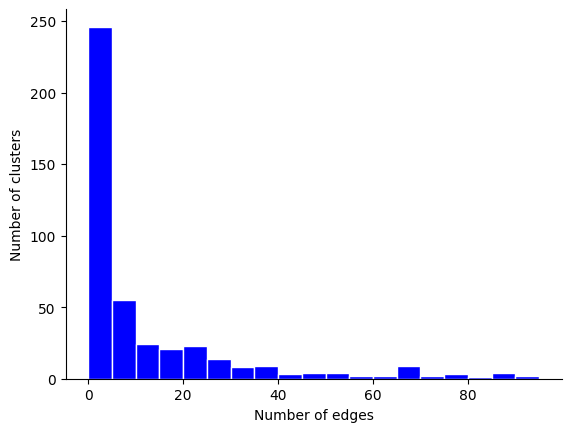

In [11]:
plt.hist(
    [len(clust["graph"]) for clust in cluster_dict.values()],
    bins=np.arange(0, 100, 5),
    color="blue",
    ec="white",
)
plt.xlabel("Number of edges")
plt.ylabel("Number of clusters")
sns.despine()

In [12]:
deg_df = pd.read_excel(
    deg_file_path,
    sheet_name="Table_S4A_DEGs_coral",
    header=1,
    index_col=0,
).rename(
    {
        "DE_Heat": "DE_Heat_control",
        "DE_Antibiotics": "DE_Antibiotics_control",
        "DE_Antibiotics.Heat": "DE_Antibiotics.Heat_control",
    },
    axis=1,
)
deg_df.index = deg_df.index + "-RA"

In [13]:
expression_df = pd.read_csv(expression_file_path, sep="\t", skiprows=1)
expression_df.columns = [i.split("/")[-1].split("_")[0] for i in expression_df.columns]
expression_df["Geneid"] = expression_df["Geneid"] + "-RA"
expression_df = expression_df.set_index("Geneid")
expression_df = expression_df.iloc[:, 5:]

---

# Compute clusters based just on function

In [14]:
go_assigned = set()
for clust in tqdm(cluster_dict.values()):
    for m in clust["members"]:
        go_assigned.update(go_map.get(m, []))
go_assigned = sorted(list(go_assigned.intersection(go_database.keys())))

logger.info(f"{len(go_assigned)} GO terms assigned")

100%|██████████| 468/468 [00:00<00:00, 27080.93it/s]
2026-05-07 11:53:10.379 | INFO     | __main__:<module>:7 - 10799 GO terms assigned


In [15]:
proteins_in_clusters = []
for clust in tqdm(cluster_dict.values()):
    proteins_in_clusters.extend(clust["members"])
    proteins_in_clusters.extend(list(clust["recipe"]["degree"]["0.75"]))
proteins_in_clusters = sorted(list(set(proteins_in_clusters)))
logger.info(f"{len(proteins_in_clusters)} proteins in clusters")

100%|██████████| 468/468 [00:00<00:00, 571284.71it/s]
2026-05-07 11:53:11.387 | INFO     | __main__:<module>:6 - 7242 proteins in clusters


In [16]:
with open(
    "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/afdb_download/pdam_protein_list.txt",
    "w",
) as f:
    for prot in proteins_in_clusters:
        f.write(prot.split("-RA")[0] + "\n")

In [17]:
def protein_GO_bit_vector(
    protein_id, go_map, full_go_list, id_col="seq", go_col="GO_ids"
):
    go_bv = np.zeros(len(full_go_list))
    prot_go = go_map.get(protein_id)
    if prot_go is not None:
        for gid in prot_go:
            if gid in full_go_list:
                go_bv[full_go_list.index(gid)] = 1
    return go_bv


# Compute GO bit vectors for each protein
protein_GO_bvs = {}
for pid in tqdm(proteins_in_clusters):
    protein_GO_bvs[pid] = protein_GO_bit_vector(pid, go_map, go_assigned)

100%|██████████| 7242/7242 [01:01<00:00, 117.78it/s]


In [18]:
X = np.array([protein_GO_bvs[pid] for pid in proteins_in_clusters], dtype=np.float32)

intersection = X @ X.T
row_sums = X.sum(axis=1)
union = row_sums[:, None] + row_sums[None, :] - intersection

function_jaccard_similarity = np.divide(intersection, union, where=union > 0)

/tmp/ipykernel_242186/2657135209.py:7: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  function_jaccard_similarity = np.divide(intersection, union, where=union > 0)


In [19]:
function_jaccard_df = pd.DataFrame(
    function_jaccard_similarity,
    index=proteins_in_clusters,
    columns=proteins_in_clusters,
)

In [20]:
# Initial clustering

init_k = 500
random_seed = 42

SC = SpectralClustering(
    n_clusters=init_k,
    assign_labels="discretize",
    random_state=random_seed,
    affinity="precomputed",
)
SC.fit(function_jaccard_similarity)

/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,"n_clusters n_clusters: int, default=8The dimension of the projection subspace.",500
,"eigen_solver eigen_solver: {'arpack', 'lobpcg', 'amg'}, default=NoneThe eigenvalue decomposition strategy to use. AMG requires pyamgto be installed. It can be faster on very large, sparse problems,but may also lead to instabilities. If None, then ``'arpack'`` isused. See [4]_ for more details regarding `'lobpcg'`.",None
,"n_components n_components: int, default=NoneNumber of eigenvectors to use for the spectral embedding. If None,defaults to `n_clusters`.",None
,"random_state random_state: int, RandomState instance, default=NoneA pseudo random number generator used for the initializationof the lobpcg eigenvectors decomposition when `eigen_solver =='amg'`, and for the K-Means initialization. Use an int to makethe results deterministic across calls (See:term:`Glossary `)... note:: When using `eigen_solver == 'amg'`, it is necessary to also fix the global numpy seed with `np.random.seed(int)` to get deterministic results. See https://github.com/pyamg/pyamg/issues/139 for further information.",42
,"n_init n_init: int, default=10Number of time the k-means algorithm will be run with differentcentroid seeds. The final results will be the best output of n_initconsecutive runs in terms of inertia. Only used if``assign_labels='kmeans'``.",10
,"gamma gamma: float, default=1.0Kernel coefficient for rbf, poly, sigmoid, laplacian and chi2 kernels.Ignored for ``affinity='nearest_neighbors'``, ``affinity='precomputed'``or ``affinity='precomputed_nearest_neighbors'``.",1.0
,"affinity affinity: str or callable, default='rbf'How to construct the affinity matrix. - 'nearest_neighbors': construct the affinity matrix by computing a graph of nearest neighbors. - 'rbf': construct the affinity matrix using a radial basis function (RBF) kernel. - 'precomputed': interpret ``X`` as a precomputed affinity matrix, where larger values indicate greater similarity between instances. - 'precomputed_nearest_neighbors': interpret ``X`` as a sparse graph of precomputed distances, and construct a binary affinity matrix from the ``n_neighbors`` nearest neighbors of each instance. - one of the kernels supported by :func:`~sklearn.metrics.pairwise.pairwise_kernels`.Only kernels that produce similarity scores (non-negative values thatincrease with similarity) should be used. This property is not checkedby the clustering algorithm.",'precomputed'
,"n_neighbors n_neighbors: int, default=10Number of neighbors to use when constructing the affinity matrix usingthe nearest neighbors method. Ignored for ``affinity='rbf'``.",10
,"eigen_tol eigen_tol: float, default=""auto""Stopping criterion for eigen decomposition of the Laplacian matrix.If `eigen_tol=""auto""` then the passed tolerance will depend on the`eigen_solver`:- If `eigen_solver=""arpack""`, then `eigen_tol=0.0`;- If `eigen_solver=""lobpcg""` or `eigen_solver=""amg""`, then `eigen_tol=None` which configures the underlying `lobpcg` solver to automatically resolve the value according to their heuristics. See, :func:`scipy.sparse.linalg.lobpcg` for details.Note that when using `eigen_solver=""lobpcg""` or `eigen_solver=""amg""`values of `tol<1e-5` may lead to convergence issues and should beavoided... versionadded:: 1.2 Added 'auto' option.",'auto'
,"assign_labels assign_labels: {'kmeans', 'discretize', 'cluster_qr'}, default='kmeans'The strategy for assigning labels in the embedding space. There are twoways to assign labels after the Laplacian embedding. k-means is apopular choice, but it can be sensitive to initialization.Discretization is another approach which is less sensitive to randominitialization [3]_.The cluster_qr method [5]_ directly extract clusters from eigenvectorsin spectral clustering. In contrast to k-means and discretization, cluster_qrhas no tuning parameters and runs no iterations, yet may outperformk-means and discretization in terms of both quality and speed... versionchanged:: 1.1 Added new labeling method 'c

In [21]:
# Recursive clustering of large clusters
min_cluster_size = 3
cluster_divisor = 20


def extract_clusters(
    SC: SpectralClustering, og_clust: list, og_csize: int, verbosity=2
):
    subCs = []
    for label in set(SC.labels_):  # go through all labels
        # make a list of all nodes in the cluster assigned to given label
        subCs.append([og_clust[i] for i in range(og_csize) if SC.labels_[i] == label])

    if verbosity > 0:
        to_print = f"Cluster of size {og_csize} -> split into {len(subCs)} clusters "

        if verbosity > 1:
            to_print += "of sizes: "
            for subC in subCs:
                to_print += f"{len(subC)}/"
        logger.info(to_print[:-1])

    # return list of tuples of priority of cluster and list of nodes in cluster
    return [(1 / len(subC), subC) for subC in subCs]


clusts = [
    [j for j in range(len(SC.labels_)) if SC.labels_[j] == i]
    for i in range(max(SC.labels_) + 1)
    if i in SC.labels_
]
clusts.sort(key=lambda x: len(x), reverse=True)

logger.info(f"Initial Clustering: {len(clusts)} clusters")
clustQ: PriorityQueue[tuple[float, list[int]]] = PriorityQueue()
for c in clusts:
    clustQ.put((1 / len(c), c))

logger.info(f"Splitting large clusters into {cluster_divisor} clusters...")
while True:
    priority, c = clustQ.get()
    csize = int(1 / priority)

    n_clusters = int(
        np.round(csize / cluster_divisor)
    )  # NOTE: this changed so that we are left with clusters of max size 30

    if n_clusters < 2:
        clustQ.put((priority, c))
        break

    SC2 = SpectralClustering(
        n_clusters=n_clusters,
        assign_labels="discretize",
        random_state=random_seed,
        affinity="precomputed",
    )
    SC2.fit(function_jaccard_similarity[c, :][:, c])

    subClusts = extract_clusters(SC2, c, csize, verbosity=2)
    for subClust in subClusts:
        clustQ.put(subClust)

logger.info(f"Removing small clusters (<{min_cluster_size})...")
filtered_clusters = []
while not clustQ.empty():
    _, c = clustQ.get()
    filtered_clusters.append(c)
filtered_clusters = [i for i in filtered_clusters if len(i) >= min_cluster_size]
logger.info(f"Final Clustering: {len(filtered_clusters)} clusters")

2026-05-07 11:55:06.914 | INFO     | __main__:<module>:32 - Initial Clustering: 411 clusters
2026-05-07 11:55:06.916 | INFO     | __main__:<module>:37 - Splitting large clusters into 20 clusters...
2026-05-07 11:55:07.130 | INFO     | __main__:extract_clusters:20 - Cluster of size 873 -> split into 44 clusters of sizes: 12/1/4/18/1/1/1/60/186/1/12/4/1/17/3/19/1/26/5/14/10/12/13/2/9/11/249/6/8/14/12/11/7/13/20/13/15/8/5/13/10/8/12/5
2026-05-07 11:55:07.228 | INFO     | __main__:extract_clusters:20 - Cluster of size 429 -> split into 21 clusters of sizes: 160/4/5/3/7/2/3/4/6/6/11/4/4/6/6/88/28/7/12/49/14
/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
2026-05-07 11:55:07.236 | INFO     | __main__:extract_clusters:20 - Cluster of size 255 -> split into 12 clusters of sizes: 56/8/3/6/7/8/3/15/12/31/7

2026-05-07 11:55:07.365 | INFO     | __main__:extract_clusters:20 - Cluster of size 53 -> split into 3 clusters of sizes: 43/1/9
2026-05-07 11:55:07.367 | INFO     | __main__:extract_clusters:20 - Cluster of size 52 -> split into 3 clusters of sizes: 18/17/17
2026-05-07 11:55:07.369 | INFO     | __main__:extract_clusters:20 - Cluster of size 51 -> split into 3 clusters of sizes: 31/8/12
2026-05-07 11:55:07.371 | INFO     | __main__:extract_clusters:20 - Cluster of size 51 -> split into 3 clusters of sizes: 4/1/46
2026-05-07 11:55:07.373 | INFO     | __main__:extract_clusters:20 - Cluster of size 49 -> split into 2 clusters of sizes: 48/1
2026-05-07 11:55:07.376 | INFO     | __main__:extract_clusters:20 - Cluster of size 48 -> split into 2 clusters of sizes: 44/4
2026-05-07 11:55:07.378 | INFO     | __main__:extract_clusters:20 - Cluster of size 48 -> split into 2 clusters of sizes: 19/29
2026-05-07 11:55:07.380 | INFO     | __main__:extract_clusters:20 - Cluster of size 48 -> split int

In [22]:
from philharmonic.utils import hash_cluster

clusters_by_function_names = [
    [proteins_in_clusters[i] for i in cl] for cl in filtered_clusters
]

clusters_by_function = {}
for cl in clusters_by_function_names:
    members = cl
    uqid = hash_cluster(cl)
    subgraph = full_G.subgraph(cl)
    clusters_by_function[uqid] = {
        "members": members,
        "graph": [
            (i[0], i[1], subgraph.get_edge_data(i[0], i[1])["weight"])
            for i in subgraph.edges()
        ],
    }
logger.info(f"{len(clusters_by_function)} clusters by function")

2026-05-07 11:55:07.749 | INFO     | __main__:<module>:19 - 639 clusters by function


---

## Raw Expression

In [23]:
philharmonic_proteins = set.union(
    *[
        set(i["members"] + list(i["recipe"]["degree"]["0.75"]))
        for i in cluster_dict.values()
    ]
)
function_proteins = set.union(*[set(cl) for cl in clusters_by_function_names])
intersection_proteins = philharmonic_proteins.intersection(function_proteins)
logger.info(f"{len(philharmonic_proteins)} proteins in original clusters")
logger.info(f"{len(function_proteins)} proteins in function-based clusters")
logger.info(
    f"{len(intersection_proteins)} proteins in intersection of original and function-based clusters"
)
expression_philharmonic = expression_df.loc[
    expression_df.index.intersection(intersection_proteins)
]

2026-05-07 11:55:24.381 | INFO     | __main__:<module>:9 - 7242 proteins in original clusters
2026-05-07 11:55:24.382 | INFO     | __main__:<module>:10 - 7069 proteins in function-based clusters
2026-05-07 11:55:24.383 | INFO     | __main__:<module>:11 - 7069 proteins in intersection of original and function-based clusters


In [24]:
logger.info(f"Expression data has shape: {expression_philharmonic.shape}")
expression_philharmonic.head()

2026-05-07 11:55:24.669 | INFO     | __main__:<module>:1 - Expression data has shape: (7069, 47)


,Hw1-1a,Hw1-1b,Hw1-1c,Hw1-4a,Hw1-4b,Hw1-4c,Hw1-5a,Hw1-5b,Hw1-5c,Hw1-6a,...,Wt2-1c,Wt2-4a,Wt2-4b,Wt2-4c,Wt2-5a,Wt2-5b,Wt2-5c,Wt2-6a,Wt2-6b,Wt2-6c
Geneid,,,,,,,,,,,,,,,,,,,,,
pdam_00021773-RA,292,72,77,26,8,37,353,51,271,380,...,6,5,34,16,30,23,2,28,13,25
pdam_00022011-RA,1,10,6,8,15,7,17,27,10,18,...,17,23,74,101,47,31,39,67,74,79
pdam_00012251-RA,925,1950,1260,624,1104,1154,2973,1975,1960,2170,...,1215,1117,1905,1670,1574,1933,1502,1813,1460,1686
pdam_00012254-RA,110,278,197,159,164,253,362,523,424,356,...,370,334,618,514,577,550,353,715,347,502
pdam_00012261-RA,5,7,26,30,26,14,68,103,50,46,...,104,30,188,279,156,203,100,273,246,185


Following Connelly et al., we apply a variance-stabilizing transformation to expression counts, then compute the pairwise bi-weighted mid-correlation between genes.

In [25]:
def vst(counts, alpha=1):
    """
    Apply a variance stabilizing transformation to count data.

    Parameters:
    counts (array-like): The input count data
    alpha (float): A small constant to avoid taking log of zero

    Returns:
    numpy.ndarray: The transformed data
    """
    counts = np.asarray(counts)
    return np.log2(counts + np.sqrt(counts + alpha**2))


def bicor_matrix(X, epsilon=1e-12):
    """
    Compute pairwise bi-weight mid-correlation for all genes.

    Parameters:
    X (np.ndarray): A 2D array of shape (n_genes, n_samples) containing normalized count data
    epsilon (float): Small value to avoid division by zero

    Returns:
    np.ndarray: A 2D array of shape (n_genes, n_genes) containing pairwise correlations
    """
    # Compute median and MAD for each gene
    gene_medians = np.median(X, axis=1)
    gene_mads = np.median(np.abs(X - gene_medians[:, np.newaxis]), axis=1)

    # Handle genes with zero MAD
    gene_mads = np.maximum(gene_mads, epsilon)

    # Compute U matrix
    U = (X - gene_medians[:, np.newaxis]) / (9 * gene_mads[:, np.newaxis])

    # Compute weights
    W = (1 - U**2) ** 2
    W[np.abs(U) >= 1] = 0

    # Compute weighted centered expression
    X_weighted = W * (X - gene_medians[:, np.newaxis])

    # Compute pairwise correlations
    norms = np.sqrt(np.sum(X_weighted**2, axis=1))
    norms = np.maximum(norms, epsilon)  # Avoid division by zero
    corr_matrix = np.dot(X_weighted, X_weighted.T) / np.outer(norms, norms)

    # Set diagonal to 1 and handle numerical instability
    np.fill_diagonal(corr_matrix, 1)
    corr_matrix = np.clip(corr_matrix, -1, 1)

    return corr_matrix

In [26]:
dense_df = expression_df[
    np.sum(expression_df > 0, axis=1) > expression_df.shape[1] * 0.5
]
dense_corr = bicor_matrix(vst(dense_df.values))
dense_corr_df = pd.DataFrame(
    dense_corr,
    index=dense_df.index,
    columns=dense_df.index,
)
logger.info(f"Expression data has shape: {expression_df.shape}")
logger.info(f"Dense correlation matrix has shape: {dense_corr_df.shape}")
logger.info(f"Dense correlation matrix has {np.sum(np.isnan(dense_corr))} NaN values")

2026-05-07 11:55:29.403 | INFO     | __main__:<module>:10 - Expression data has shape: (26077, 47)
2026-05-07 11:55:29.405 | INFO     | __main__:<module>:11 - Dense correlation matrix has shape: (20496, 20496)
2026-05-07 11:55:29.853 | INFO     | __main__:<module>:12 - Dense correlation matrix has 0 NaN values


In [27]:
# cluster_proteins = set.union(*[set(i["members"]) for i in cluster_dict.values()])
removed_proteins = set(expression_df.index).difference(dense_corr_df.index)
removed_cluster_proteins = intersection_proteins.intersection(removed_proteins)
logger.info(
    f"Removed {len(removed_proteins)} proteins from the expression data because of sparsity, {len(removed_cluster_proteins)} which were in clusters."
)

2026-05-07 11:55:29.868 | INFO     | __main__:<module>:4 - Removed 5581 proteins from the expression data because of sparsity, 784 which were in clusters.


---

# Combine our clusters with function clusters 

In [28]:
def extract_cluster_correlations(
    cluster_members, correlation_df, summary_func=None, dataframe=False
):
    """
    Extract the lower diagonal of pairwise correlations for a set of genes.

    Parameters:
    cluster_members (list): A list of gene names
    correlation_df (pd.DataFrame): A DataFrame containing pairwise correlations

    Returns:
    pd.DataFrame: A DataFrame containing pairwise correlations for the input genes
    """
    members = list(set(cluster_members).intersection(correlation_df.index))
    cluster_correlations = correlation_df.loc[members, members].values[
        np.tril_indices(len(members), k=-1)
    ]
    if summary_func:
        return summary_func(cluster_correlations)
    elif dataframe:
        return correlation_df.loc[members, members]
    else:
        return cluster_correlations

In [29]:
cluster_correlations = {
    "Philharmonic": [
        extract_cluster_correlations(
            c["members"] + list(c["recipe"]["degree"]["0.75"]),
            dense_corr_df,
            np.median,
        )
        for c in tqdm(cluster_dict.values(), total=len(cluster_dict))
    ],
    "GO_Clusters": [
        extract_cluster_correlations(c["members"], dense_corr_df, np.median)
        for c in tqdm(clusters_by_function.values(), total=len(clusters_by_function))
    ],
}

 88%|████████▊ | 564/639 [00:01<00:00, 438.46it/s]/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/ssledzieski/Projects/philharmonic-experiments/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
 97%|█████████▋| 617/639 [00:02<00:00, 465.66it/s]/mnt/home/ssledzieski/Projects/philharmonic-ex

In [30]:
plot_df = []
for key, corrs in cluster_correlations.items():
    for corr in corrs:
        plot_df.append(
            {"Median Bi-Weight Mid Correlation": corr, "Expression Data": key}
        )
plot_df = pd.DataFrame(plot_df)
plot_df.head()

,Median Bi-Weight Mid Correlation,Expression Data
0,0.400157,Philharmonic
1,0.480713,Philharmonic
2,0.472988,Philharmonic
3,0.705354,Philharmonic
4,0.463314,Philharmonic


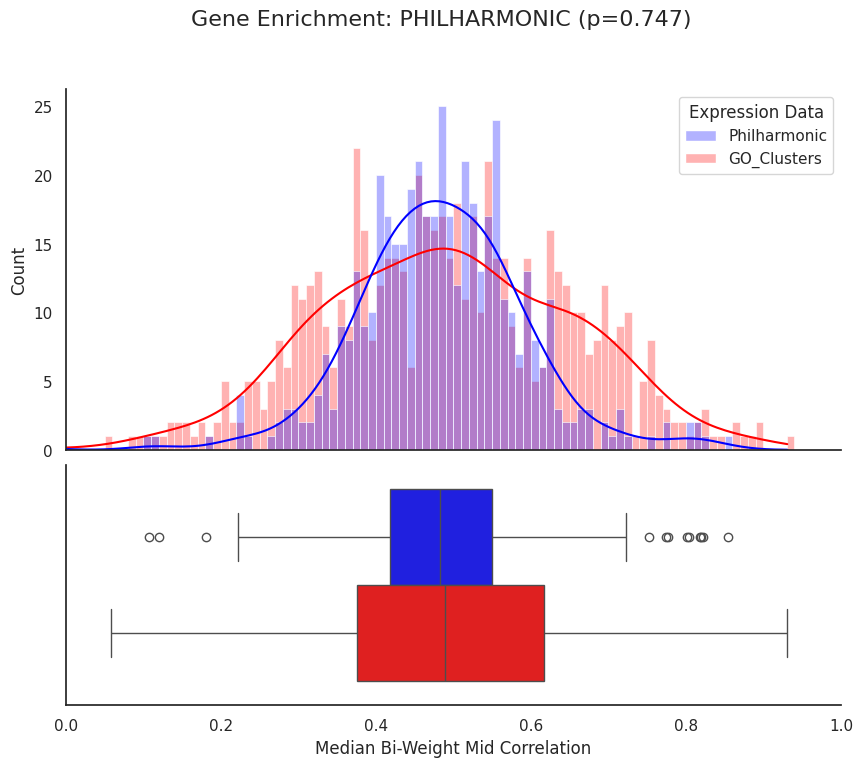

In [35]:
sns.set_palette("colorblind")
sns.set_theme(style="white", palette="pastel", font_scale=1)

phil_correlations = np.array(cluster_correlations["Philharmonic"])
phil_correlations = phil_correlations[~np.isnan(phil_correlations)]

func_correlations = np.array(cluster_correlations["GO_Clusters"])
func_correlations = func_correlations[~np.isnan(func_correlations)]

tstat_rand, p_rand = ttest_ind(
    phil_correlations, func_correlations, alternative="greater"
)

# plot_df = cluster_corr_df.melt("key").rename(
#     {"value": "Median Bi-Weight Mid Correlation", "variable": "Expression Data"}, axis=1
# )

# Create figure and gridspec
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 1, height_ratios=[3, 2], hspace=0.05)

# Create top subplot for histogram
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])

sns.histplot(
    data=plot_df,
    x="Median Bi-Weight Mid Correlation",
    hue="Expression Data",
    alpha=0.3,
    kde=True,
    bins=np.arange(-0.1, 1.05, 0.01),
    palette=["blue", "red"],
    common_norm=False,
    ec="white",
    ax=ax0,
)

sns.boxplot(
    data=plot_df,
    x="Median Bi-Weight Mid Correlation",
    hue="Expression Data",
    palette=["blue", "red"],
    ax=ax1,
)

# set xlim 0 to 1
plt.xlim(0, 1)

ax0.set_xlabel("")  # Remove x-label from top plot
ax1.set_xlabel("Median Bi-Weight Mid Correlation")  # Add x-label to bottom plot
ax0.set_xticklabels([])  # Remove x-ticks from top plot


ax0.set_xlim(ax1.get_xlim())  # Align the x-axis of both subplots
ax1.get_legend().remove()  # Remove legend from bottom plot

plt.suptitle(f"Gene Enrichment: PHILHARMONIC (p={p_rand:.3})", fontsize=16)

# Show the plot
sns.despine()
plt.savefig(
    IMG_DIR / "vs_go_clusters_gexp_enrichment_combined.svg",
    bbox_inches="tight",
    dpi=300,
)
plt.show()

---
# Evalute network accuracy of function clusters

In [36]:
phil_num_edges = []
phil_num_cc = []
func_num_edges = []
func_num_cc = []

for k, clust in cluster_dict.items():
    dscript_subgraph = full_G.subgraph(
        clust["members"] + list(clust["recipe"]["degree"]["0.75"])
    )
    num_edges = dscript_subgraph.number_of_edges()
    num_cc = nx.number_connected_components(dscript_subgraph)
    phil_num_edges.append(num_edges)
    phil_num_cc.append(num_cc)

for k, clust in clusters_by_function.items():
    dscript_subgraph = full_G.subgraph(clust["members"])
    num_edges = dscript_subgraph.number_of_edges()
    num_cc = nx.number_connected_components(dscript_subgraph)
    func_num_edges.append(num_edges)
    func_num_cc.append(num_cc)

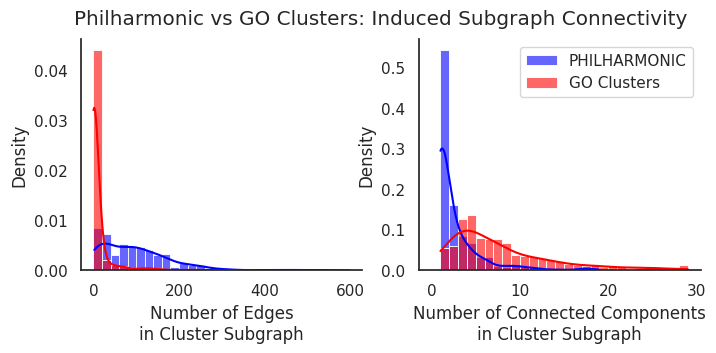

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))

sns.histplot(
    phil_num_edges,
    label="PHILHARMONIC",
    alpha=0.6,
    bins=np.arange(0, max(phil_num_edges + func_num_edges) + 1, 20),
    color="blue",
    stat="density",
    kde=True,
    ax=ax[0],
)
sns.histplot(
    func_num_edges,
    label="GO Clusters",
    bins=np.arange(0, max(phil_num_edges + func_num_edges) + 1, 20),
    color="red",
    stat="density",
    alpha=0.6,
    kde=True,
    ax=ax[0],
)

sns.histplot(
    phil_num_cc,
    alpha=0.6,
    label="PHILHARMONIC",
    bins=np.arange(0, max(phil_num_cc + func_num_cc) + 1, 1),
    color="blue",
    ec="white",
    kde=True,
    stat="density",
    ax=ax[1],
)
sns.histplot(
    func_num_cc,
    alpha=0.6,
    label="GO Clusters",
    bins=np.arange(0, max(phil_num_cc + func_num_cc) + 1, 1),
    color="red",
    stat="density",
    ec="white",
    kde=True,
    ax=ax[1],
)
ax[0].set_xlabel("Number of Edges\nin Cluster Subgraph")
ax[1].set_xlabel("Number of Connected Components\nin Cluster Subgraph")
ax[0].set_ylabel("Density")
ax[1].set_ylabel("Density")
plt.suptitle("Philharmonic vs GO Clusters: Induced Subgraph Connectivity")
plt.legend()
sns.despine()
plt.savefig(
    IMG_DIR / "vs_go_clusters_induced_subgraph_connectivity.svg",
    bbox_inches="tight",
    dpi=300,
)

plt.show()